In [2]:
import numpy as np
import pandas as pd
import matplotlib.pylab as plt
import seaborn as sns

In [3]:
# Load the dataset
df = pd.read_csv('../csv/clubs.csv')

print(df.dtypes)

# Display some rows of the dataset
df

club_id                      int64
club_code                   object
name                        object
domestic_competition_id     object
total_market_value         float64
squad_size                   int64
average_age                float64
foreigners_number            int64
foreigners_percentage      float64
national_team_players        int64
stadium_name                object
stadium_seats                int64
net_transfer_record         object
coach_name                 float64
last_season                  int64
url                         object
dtype: object


,club_id,club_code,name,domestic_competition_id,total_market_value,squad_size,average_age,foreigners_number,foreigners_percentage,national_team_players,stadium_name,stadium_seats,net_transfer_record,coach_name,last_season,url
0,105,sv-darmstadt-98,Sportverein Darmstadt 1898 e. V.,L1,NaN,30,26.4,11,36.7,1,Merck-Stadion am Böllenfalltor,17810,€-1.60m,NaN,2023,https://www.transfermarkt.co.uk/sv-darmstadt-9...
1,11127,ural-ekaterinburg,FK Ural Yekaterinburg,RU1,NaN,25,28.2,13,52.0,5,Yekaterinburg Arena,23000,€-770k,NaN,2023,https://www.transfermarkt.co.uk/ural-ekaterinb...
2,114,besiktas-istanbul,Beşiktaş Jimnastik Kulübü,TR1,NaN,32,27.4,16,50.0,13,Tüpraş Stadyumu,42590,€-14.50m,NaN,2023,https://www.transfermarkt.co.uk/besiktas-istan...
3,12,as-rom,Associazione Sportiva Roma,IT1,NaN,26,27.4,17,65.4,17,Olimpico di Roma,73261,+€65.20m,NaN,2023,https://www.transfermarkt.co.uk/as-rom/startse...
4,148,tottenham-hotspur,Tottenham Hotspur Football Club,GB1,NaN,29,26.2,21,72.4,22,Tottenham Hotspur Stadium,62062,€-130.40m,NaN,2023,https://www.transfermarkt.co.uk/tottenham-hots...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
421,68608,cf-os-belenenses,CF Os Belenenses,PO1,NaN,30,25.7,5,16.7,0,Estádio do Restelo,19980,+-0,NaN,2017,https://www.transfermarkt.co.uk/cf-os-belenens...
422,724,fc-volendam,Football Club Volendam,NL1,NaN,29,22.8,14,48.3,3,Kras Stadion,7384,+€1.80m,NaN,2023,https://www.transfermarkt.co.uk/fc-volendam/st...
423,800,atalanta-bergamo,Atalanta Bergamasca Calcio S.p.a.,IT1,NaN,25,27.2,17,68.0,15,Gewiss Stadium,21747,+€87.00m,NaN,2023,https://www.transfermarkt.co.uk/atalanta-berga...
424,979,moreirense-fc,Moreirense Futebol Clube,PO1,NaN,26,26.0,17,65.4,2,Estádio C. J. de Almeida Freitas,6153,€-2.05m,NaN,2023,https://www.transfermarkt.co.uk/moreirense-fc/...


## Data Exploration
The dataset contains 16 columns and 426 rows describing different football clubs. The columns are:
- `club_id`: The unique identifier of the club
- `club_code`: The code of the club
- `name`: The name of the club
- `domestic_competition`: The domestic competition in which the club participates
- `total_market_value`: The total market value of the club
- `squad_size`: The size of the squad
- `average_age`: The average age of the squad
- `foreign_number`: The number of foreign players in the squad
- `foreign_percentage`: The percentage of foreign players in the squad
- `national_team_players`: The number of players in the national team
- `stadium_name`: The name of the stadium
- `stadium_seats`: The number of seats in the stadium
- `net_transfer_record`: The net transfer record
- `coach_name`: The name of the coach
- `last_season`: The last season played
- `url`: url that contains more information about the club

### Data Cleaning

Number of duplicate rows =  0


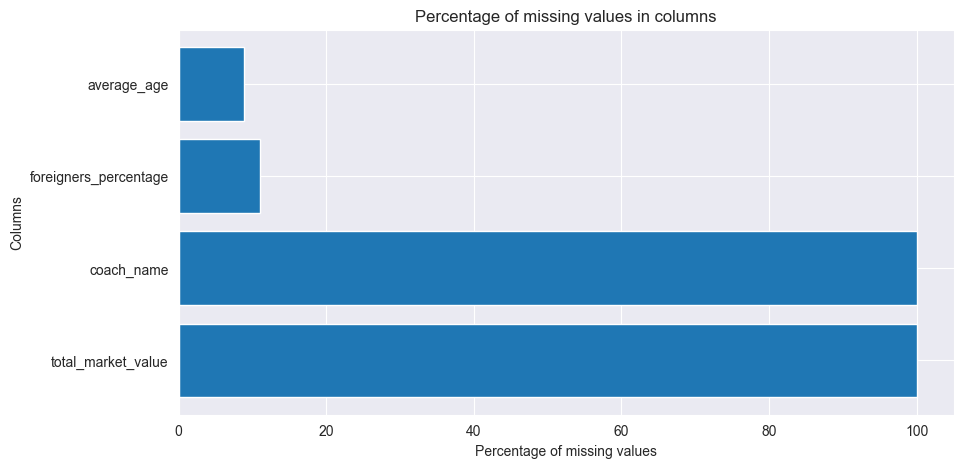

In [4]:
#check for duplicates
duplicates = df.duplicated().sum()
print('Number of duplicate rows = ', duplicates)

#mean of missing values per column
missing_values = df.isnull().mean() * 100

#filter columns with missing values
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)
plt.figure(figsize=(10, 5))
plt.barh(missing_values.index, missing_values)
plt.xlabel('Percentage of missing values')
plt.ylabel('Columns')
plt.title('Percentage of missing values in columns')
plt.show()

### Visualization of missing values
The plot above shows the percentage of missing values in columns. There is a percentage of missing values of 100% in the columns `total_market_value` and `coach_name`, we are going to drop these columns because they do not provide any useful information. The column `url` is also going to be dropped because it is not relevant for the analysis. <br>
The other columns `average_age` and `foreing_percentage` will be handled.

In [5]:
# Drop columns with missing values  
df = df.drop(columns=['total_market_value', 'coach_name', 'url'])

#filtering the columns with missing values to extract the unique values only in missing values
filtered_foreigners = df[df['foreigners_percentage'].isnull()]['foreigners_number']
unique_val_numbers = filtered_foreigners.unique()
    
if unique_val_numbers.item() == 0:
    #fill the missing values with 0
    df['foreigners_percentage'] = df['foreigners_percentage'].fillna(0)

#display the rows to see if the missing values were filled
df.query('foreigners_percentage.isnull()')

,club_id,club_code,name,domestic_competition_id,squad_size,average_age,foreigners_number,foreigners_percentage,national_team_players,stadium_name,stadium_seats,net_transfer_record,last_season


### Handling Missing Values in the DataFrame

In this section, we handled missing values, particularly in the `foreigners_percentage` column:

**Dropping Unnecessary Columns:**
   We drop the columns `total_market_value`, `coach_name`, and `url` from the DataFrame as they contain missing values, and we do not need them for our analysis.
   
We filled with the value 0 just the missing values where the percentage of foreigners is missing and the number of foreigners is 0.

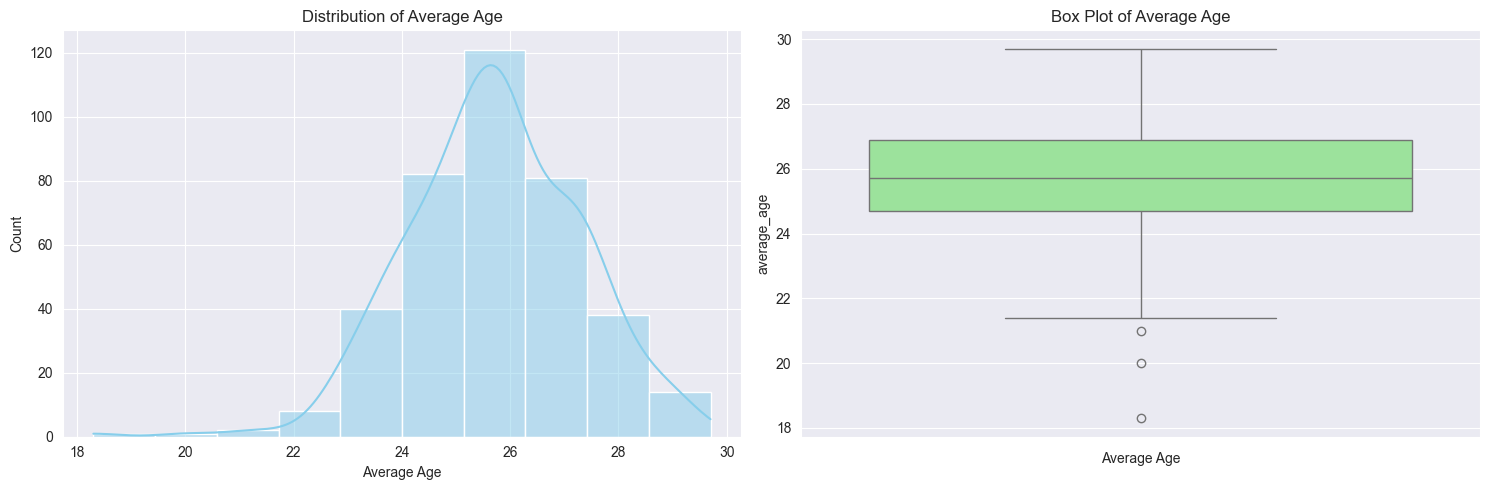

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

# Histogram of average age
sns.histplot(df['average_age'], bins=10, kde=True, color='skyblue', ax=ax[0])
ax[0].set_title('Distribution of Average Age')
ax[0].set_xlabel('Average Age')
ax[0].set_ylabel('Count')

# Box plot of average age
sns.boxplot(df['average_age'], color='lightgreen', ax=ax[1])
ax[1].set_title('Box Plot of Average Age')
ax[1].set_xlabel('Average Age')

plt.tight_layout()
plt.show()


### Distribution of Average Age
The histogram and box plot above show the distribution of the average age of the squads. The average age of the squads is approximately normally distributed with a mean around 25 years. 
We find some outliers in the box plot, with ages that are round 19 years old as the minimum and 29 years old as the maximum.

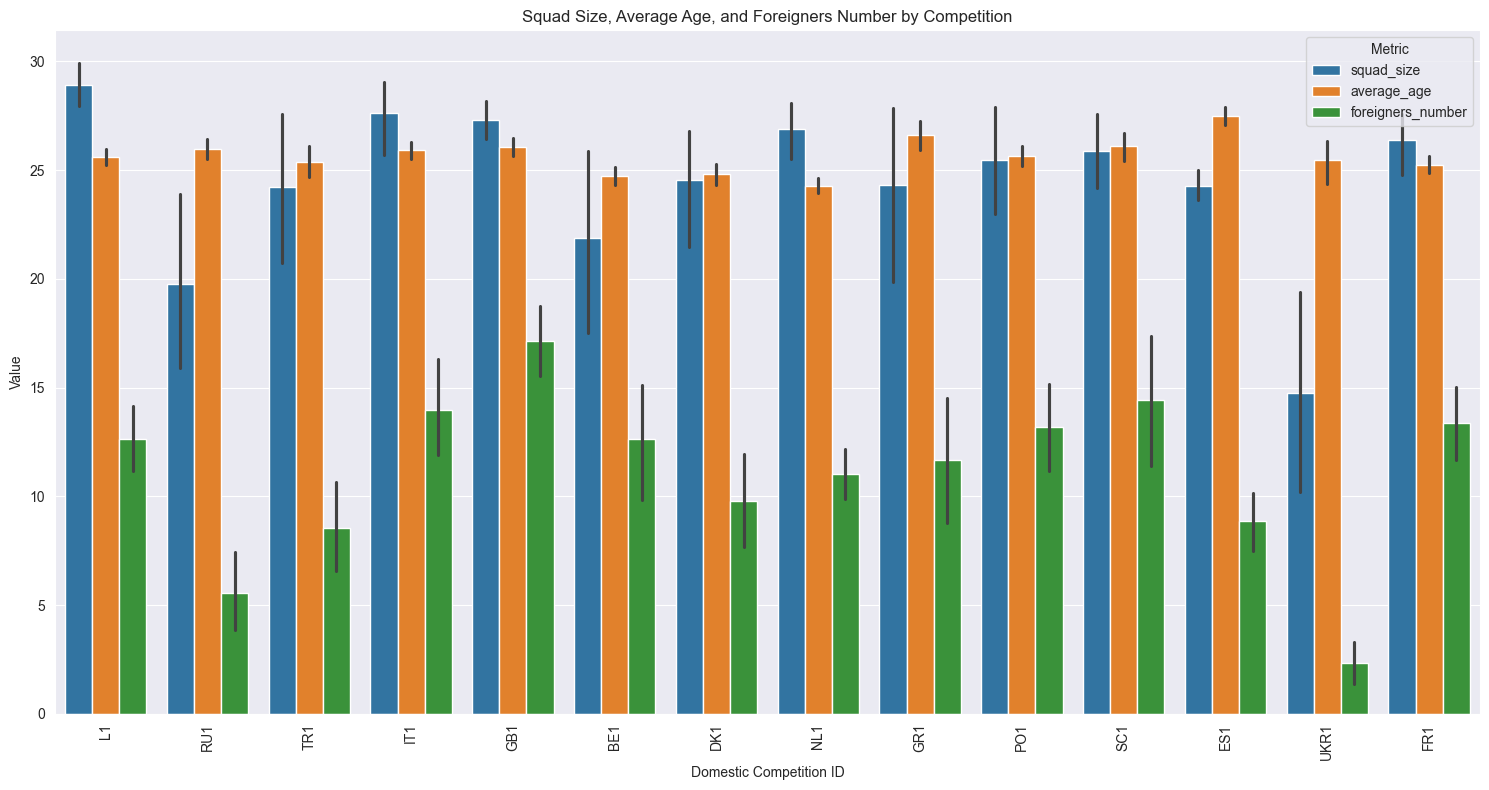

In [21]:
melted_df = pd.melt(df[['domestic_competition_id', 'squad_size', 'average_age', 'foreigners_number']],
                    id_vars='domestic_competition_id',
                    var_name='Metric',
                    value_name='Value')

# Plot the unified bar plot
plt.figure(figsize=(15, 8))
sns.barplot(x='domestic_competition_id', y='Value', hue='Metric', data=melted_df)
plt.title('Squad Size, Average Age, and Foreigners Number by Competition')
plt.xlabel('Domestic Competition ID')
plt.ylabel('Value')
plt.xticks(rotation=90)
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

### Squad Size, Average Age, and Foreigners Number by Competition
The bar plot above shows the squad size, average age, and number of foreigners by domestic competition. The foreigner number is not so different between the competitions, same thing for the average age

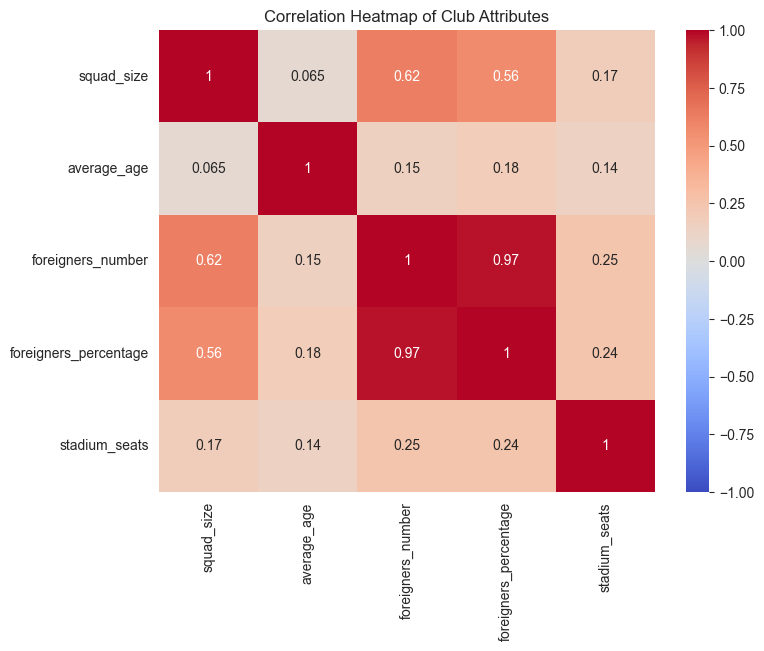

In [13]:
# Calculate the correlation matrix
correlation_matrix = df[['squad_size', 'average_age', 'foreigners_number', 'foreigners_percentage', 'stadium_seats']].corr()

# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Club Attributes')
plt.show()


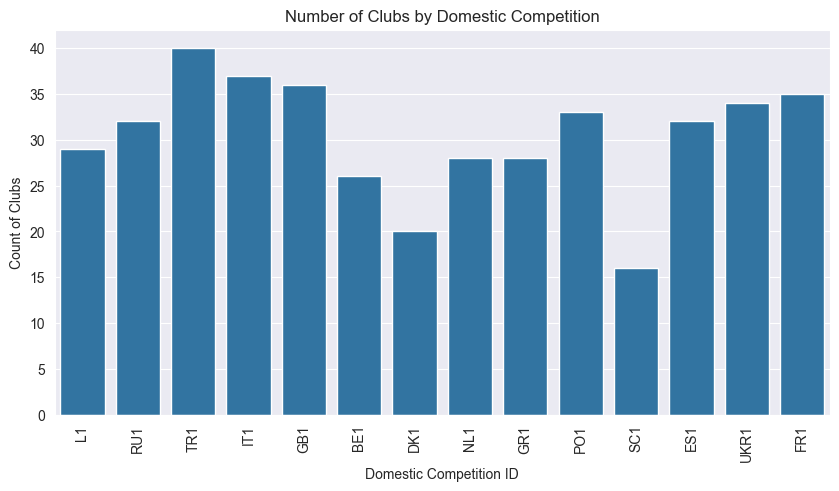

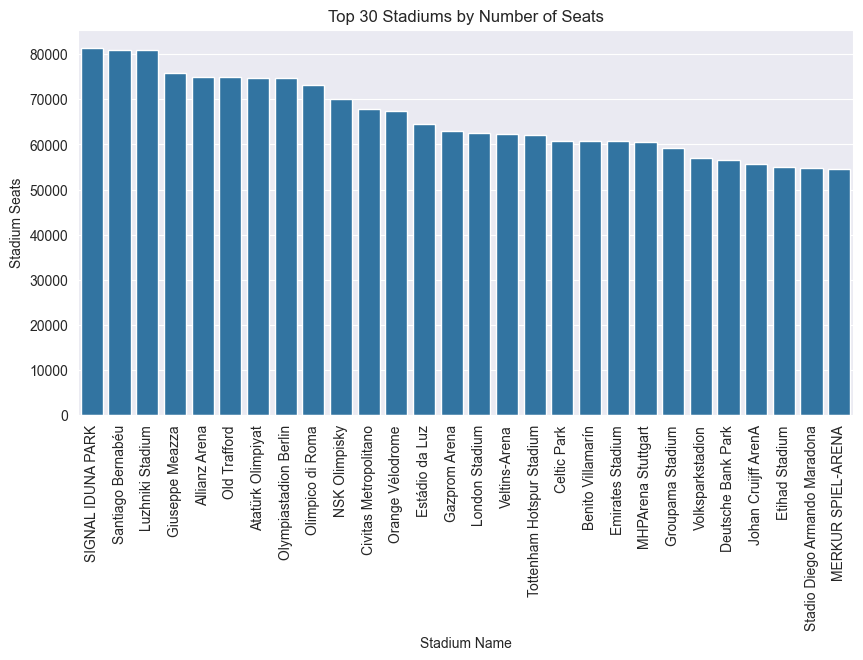

In [17]:
# Count plot for number of clubs by domestic competition
plt.figure(figsize=(10, 5))
sns.countplot(x='domestic_competition_id', data=df)
plt.title('Number of Clubs by Domestic Competition')
plt.xlabel('Domestic Competition ID')
plt.ylabel('Count of Clubs')
plt.xticks(rotation=90)
plt.show()

# Set the number of top stadiums to display
n = 30

# Sort the DataFrame by 'stadium_seats' in descending order and select the top n
top_stadiums = df.sort_values(by='stadium_seats', ascending=False).head(n)

# Create the bar plot for the top n stadiums
plt.figure(figsize=(10, 5))
sns.barplot(x='stadium_name', y='stadium_seats', data=top_stadiums)
plt.title(f'Top {n} Stadiums by Number of Seats')
plt.xlabel('Stadium Name')
plt.ylabel('Stadium Seats')
plt.xticks(rotation=90)
plt.show()

